# Assignment 2 – Diabetes Classification


# Step 1 – Understand the data

Workflow: UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Read the CSV file


In [2]:
df = pd.read_csv("/content/diabetes_binary_classification_data.csv")

print("Forme du tableau (lignes, colonnes) :", df.shape)
df.head()

Forme du tableau (lignes, colonnes) : (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Key takeaway: 253,680 rows = 253,680 survey respondents. 22 columns = 21 input features + 1 target.

Séparer X (entrées) et y (cible)


- df["Diabetes_binary"] : sélectionne une colonne du DataFrame. C'est notre cible y : ce qu'on veut prédire.
- df.drop(columns=["Diabetes_binary"]) : renvoie une copie du DataFrame sans cette colonne. Ce sont les entrées X : les informations qu'on utilise pour prédire.
- X.shape / y.shape : on vérifie que X a 21 colonnes et que y en a une seule.

Sens de la cible;  0 = pas de diabète ; 1 = prédiabète ou diabète.



Separate X (inputs) and y (target)


df["Diabetes_binary"]: selects one column of the DataFrame. This is our target y, the thing we want to predict.
df.drop(columns=["Diabetes_binary"]): returns a copy of the DataFrame without that column. These are the inputs X, the information used to make the prediction.
X.shape / y.shape: we check that X has 21 columns and y has a single one.

Meaning of the target: 0 = no diabetes; 1 = prediabetes or diabetes.

In [3]:
y = df["Diabetes_binary"]
X = df.drop(columns=["Diabetes_binary"])

print("X :", X.shape)
print("y :", y.shape)
print("Features :", list(X.columns))

X : (253680, 21)
y : (253680,)
Features : ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


Répartition des classes
- y.value_counts() : compte combien de fois chaque valeur apparaît dans y (ici combien de 0 et combien de 1).
- y.value_counts(normalize=True) : donne les proportions (entre 0 et 1) au lieu des effectifs. En multipliant par 100, on obtient des pourcentages.
- plt.bar(...) : trace un diagramme en barres. plt.title, plt.ylabel ajoutent un titre et un nom d'axe. plt.show() affiche le graphique.

Class distribution

y.value_counts(): counts how many times each value
appears in y (here, how many 0s and how many 1s).

y.value_counts(normalize=True): gives the proportions (between 0 and 1) instead of counts. Multiplying by 100 gives percentages.

plt.bar(...): draws a bar chart. plt.title and plt.ylabel add a title and an axis label. plt.show() displays the plot.

Effectifs :
 Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64 

Proportions (%) :
 Diabetes_binary
0.0    86.1
1.0    13.9
Name: proportion, dtype: float64


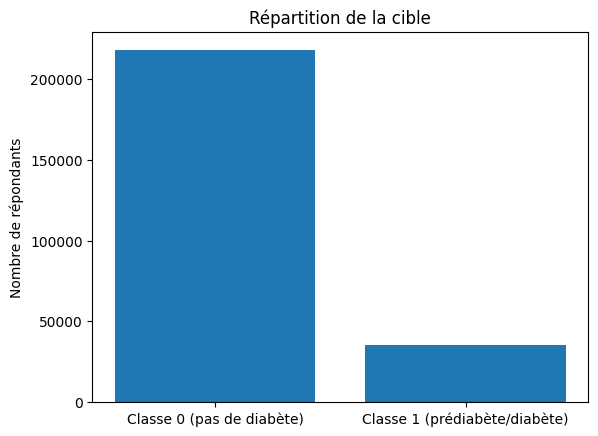

In [4]:
counts = y.value_counts()
props = y.value_counts(normalize=True) * 100

print("Effectifs :\n", counts, "\n")
print("Proportions (%) :\n", props.round(1))

plt.bar(["Classe 0 (pas de diabète)", "Classe 1 (prédiabète/diabète)"],
        [counts[0], counts[1]])
plt.title("Répartition de la cible")
plt.ylabel("Nombre de répondants")
plt.show()

La classe 1 ne représente qu'environ 14 % des données : les classes sont déséquilibrées.
Un modèle qui prédirait toujours « 0 » aurait ~86 % d'accuracy sans détecter aucune personne atteinte. C'est pour ça qu'on ne juge pas un modèle sur l'accuracy seule.

Key takeaway: class 1 is only about 14% of the data, so the classes are imbalanced. A model that always predicted “0” would reach about 86% accuracy without detecting a single person with diabetes. This is why we do not judge a model on accuracy alone.

We studied three variables: BMI, HighBP and GenHlth. The .describe() method summarizes statistics, while .value_counts() counts occurrences of each category.

BMI is numerical, HighBP is binary (0 = no, 1 = yes), and GenHlth is ordinal (from 1 = excellent to 5 = poor).

Understanding these variables is essential because numbers do not always represent actual quantities. For example, Age = 9 corresponds to the 60–64 age group, not 9 years old.

Understand three features of different types

df[["BMI", "HighBP", "GenHlth"]]: the double brackets let us pick several columns at the same time.
.describe(): gives a quick summary of a column (average, minimum, maximum...). It is useful for numbers like BMI, but less useful for categories.
df["HighBP"].value_counts(): counts how many times each value appears. This works better for categories.

The three features I chose

1. BMI (numerical). This is a real measurement of body mass index. A value of 30 simply means a BMI of 30. Because it is a true number, we can compare values, calculate averages and say that 30 is higher than 25.

2. HighBP (binary categorical). This tells us whether the person has high blood pressure. A value of 0 means “no” and a value of 1 means “yes”. It is not a quantity: 1 does not mean “more” in a measured sense, it just means the answer is yes.

3. GenHlth (ordinal categorical). This is the person’s own rating of their general health, from 1 (excellent) to 5 (poor). The categories have a natural order, so 5 is worse than 1. However, the gap between 1 and 2 is not necessarily the same as the gap between 4 and 5. The numbers are labels in an order, not exact measurements.

Why looking only at the numbers is not enough: in the CSV file, every column is stored as a number, even when it does not represent a number in real life. If we only looked at the values, we might treat Age = 9 as “9 years old”. In reality, it is a code for the 60-64 age group. Without the guide that explains what each value means, we could choose the wrong analysis or the wrong preprocessing.

In [5]:
print(df["BMI"].describe(), "\n")
print(df["HighBP"].value_counts(), "\n")
print(df["GenHlth"].value_counts().sort_index())

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64 

HighBP
0.0    144851
1.0    108829
Name: count, dtype: int64 

GenHlth
1.0    45299
2.0    89084
3.0    75646
4.0    31570
5.0    12081
Name: count, dtype: int64


# Step 2 – Explore the data (EDA)

Reminder: EDA describes patterns in the observed data. An association does not show that one variable causes diabetes.

For each type of feature we ask a question, look at evidence, and then decide what we can conclude.

FR Rappel : l’EDA décrit des motifs dans les données observées. Une association ne prouve pas qu’une variable cause le diabète. Pour chaque type de variable : question, preuve, conclusion.

Group the features by type

Plots depend on the type of variable, so we first put the column names into three lists. The types come from the “Understanding the Dataset” guide, not from the numbers in the CSV.

[col for col in X.columns if col not in ...]: a list comprehension. It goes through every column name and keeps only those that are not in the numerical or ordinal lists. What remains are the binary features.
numerical + ordinal: joins two lists into one.
len(binary): the number of items in the list.

FR On range les colonnes en 3 listes selon leur type (d’après le guide, pas d’après les chiffres du CSV). La ligne avec for ... if garde seulement les colonnes qui ne sont ni numériques ni ordinales : il reste les binaires.

In [6]:
numerical = ["BMI", "MentHlth", "PhysHlth"]
ordinal   = ["GenHlth", "Age", "Education", "Income"]
binary    = [col for col in X.columns if col not in numerical + ordinal]

print("Numerical:", numerical)
print("Ordinal  :", ordinal)
print("Binary   :", binary, "(", len(binary), "features )")

Numerical: ['BMI', 'MentHlth', 'PhysHlth']
Ordinal  : ['GenHlth', 'Age', 'Education', 'Income']
Binary   : ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'] ( 14 features )


Numerical features: compare distributions between the two classes

plt.subplots(1, 3, figsize=(15, 4)): creates a figure with 1 row and 3 plots side by side. figsize sets the size. It returns the figure and a list of plot areas called axes.
for ax, col in zip(axes, numerical): a loop that pairs each plot area with one feature, so we don’t repeat the same code three times.
df.boxplot(column=col, by="Diabetes_binary", ax=ax): draws one boxplot per class. The box covers the middle 50% of the values, the line inside is the median, and the dots are extreme values.
plt.suptitle(""): removes an automatic extra title added by pandas.
plt.tight_layout(): stops the plots from overlapping.

FR Question : BMI, MentHlth et PhysHlth sont-ils différents entre les deux classes ? La boucle for évite de répéter 3 fois le même code. Un boxplot montre la médiane (ligne), la zone centrale de 50 % des valeurs (boîte) et les valeurs extrêmes (points).

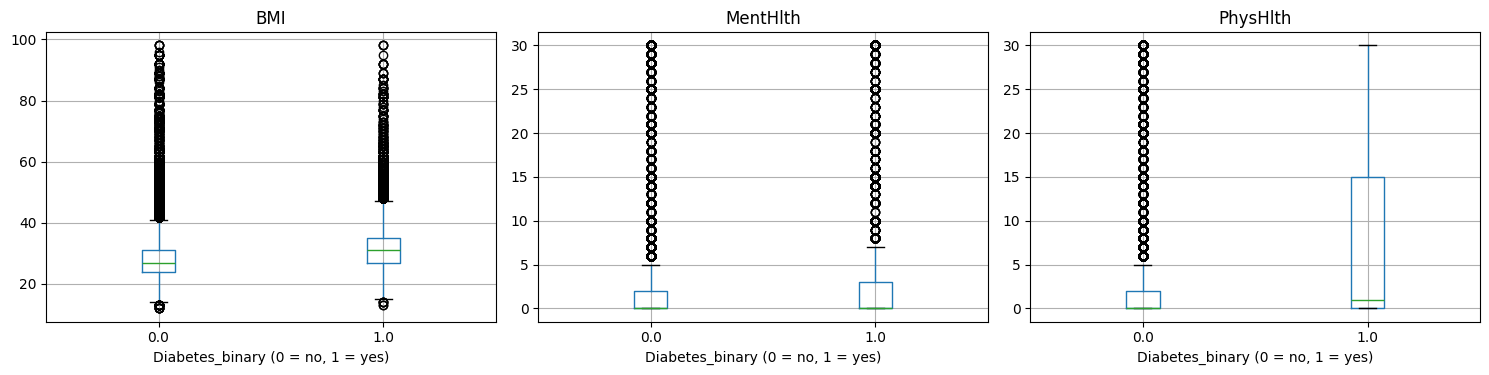

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numerical):
    df.boxplot(column=col, by="Diabetes_binary", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Diabetes_binary (0 = no, 1 = yes)")

plt.suptitle("")
plt.tight_layout()
plt.show()

Summary numbers

df.groupby("Diabetes_binary")[numerical]: splits the table into two groups (class 0 and class 1).
.mean() and .median(): compute the average and the middle value of each group. The median is less affected by extreme values than the mean.

FR groupby coupe le tableau en deux groupes (classe 0 et classe 1). On calcule ensuite la moyenne et la médiane de chaque groupe. La médiane est moins sensible aux valeurs extrêmes.

In [8]:
print("MEAN by class:")
print(df.groupby("Diabetes_binary")[numerical].mean().round(2), "\n")
print("MEDIAN by class:")
print(df.groupby("Diabetes_binary")[numerical].median())

MEAN by class:
                   BMI  MentHlth  PhysHlth
Diabetes_binary                           
0.0              27.81      2.98      3.64
1.0              31.94      4.46      7.95 

MEDIAN by class:
                  BMI  MentHlth  PhysHlth
Diabetes_binary                          
0.0              27.0       0.0       0.0
1.0              31.0       0.0       1.0


What we observe: the average BMI is higher in class 1 (31.9) than in class 0 (27.8). The average number of bad physical health days is also higher in class 1 (7.95 vs 3.64). For MentHlth and PhysHlth the median is about 0 in both classes, so most people report very few bad days and the average is pulled up by a minority.
What we can conclude: in this dataset, people with prediabetes/diabetes tend to have a higher BMI and more bad physical health days.
What we cannot conclude: that a high BMI causes diabetes. It could also be that diabetes affects physical health, or that other factors play a role.

FR Le BMI moyen est plus élevé en classe 1. Pareil pour les jours de mauvaise santé physique. On peut conclure à une association, pas à une cause.

Binary features: proportion of class 1 in each category

Question: for each yes/no feature, is the share of people with diabetes different between “no” and “yes”?

df.groupby(col)["Diabetes_binary"].mean(): because the target is 0/1, its mean is the proportion of class 1. For each category (0 or 1) we get the share of people with diabetes.
rows.append({...}): adds one line of results (a dictionary) to a list at each loop turn.
pd.DataFrame(rows): builds a table from that list.
.sort_values("difference", ascending=False): sorts the table so the biggest differences come first.

FR Comme la cible vaut 0 ou 1, sa moyenne est la proportion de classe 1. Pour chaque feature binaire, on compare cette proportion quand la valeur est 0 et quand elle est 1. On trie ensuite par différence.

In [9]:
rows = []
for col in binary:
    p = df.groupby(col)["Diabetes_binary"].mean()
    rows.append({"feature": col,
                 "% class 1 when 0": round(p[0] * 100, 1),
                 "% class 1 when 1": round(p[1] * 100, 1),
                 "difference": round((p[1] - p[0]) * 100, 1)})

binary_table = pd.DataFrame(rows).sort_values("difference", ascending=False)
binary_table

,feature,% class 1 when 0,% class 1 when 1,difference
5,HeartDiseaseorAttack,12.0,33.0,21.0
12,DiffWalk,10.5,30.7,20.2
4,Stroke,13.2,31.8,18.6
0,HighBP,6.0,24.4,18.4
1,HighChol,8.0,22.0,14.0
2,CholCheck,2.5,14.4,11.8
3,Smoker,12.1,16.3,4.2
11,NoDocbcCost,13.6,17.5,3.9
10,AnyHealthcare,11.5,14.1,2.6
13,Sex,13.0,15.2,2.2


Plot

plt.barh(names, values): horizontal bar chart. Each bar is the difference (in percentage points) in the share of class 1 between “yes” and “no”.
plt.axvline(0): draws a vertical line at 0. Bars to the right mean class 1 is more common among “yes”; bars to the left mean it is less common.
plt.gca().invert_yaxis(): puts the biggest bar at the top.

FR Chaque barre = écart de proportion de classe 1 entre “oui” et “non”. Barre à droite = plus de classe 1 chez les “oui”. Barre à gauche = moins.

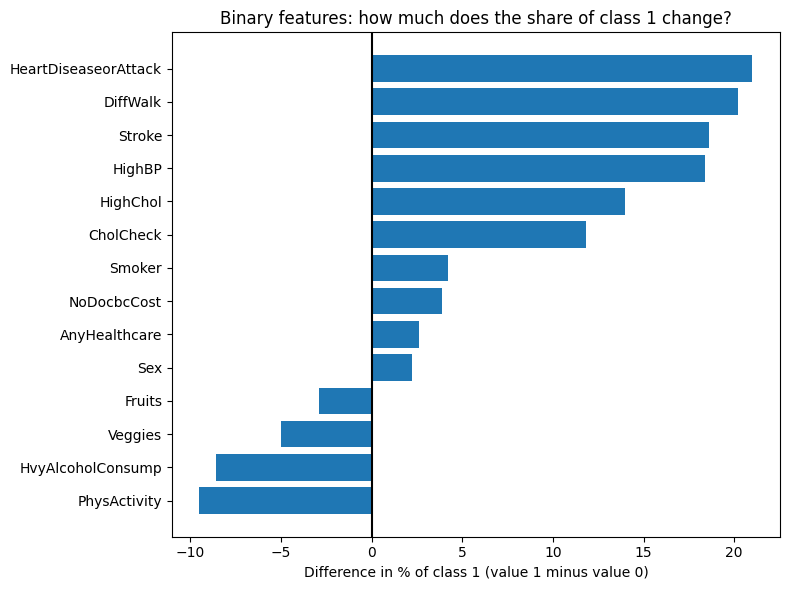

In [10]:
plt.figure(figsize=(8, 6))
plt.barh(binary_table["feature"], binary_table["difference"])
plt.axvline(0, color="black")
plt.xlabel("Difference in % of class 1 (value 1 minus value 0)")
plt.title("Binary features: how much does the share of class 1 change?")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

What we observe: the share of class 1 is much higher among people with a history of heart disease or heart attack (33.0% vs 12.0%), difficulty walking (30.7% vs 10.5%), stroke (31.8% vs 13.2%) and high blood pressure (24.4% vs 6.0%). Physical activity goes the other way: 11.6% of class 1 among active people vs 21.1% among inactive people.
What we can conclude: these health conditions are strongly associated with the target in this dataset.
What we cannot conclude: that one causes the other. Some results are surprising: heavy alcohol consumption shows a lower share of class 1 (5.8% vs 14.4%). Possible explanations (such as people changing habits after a diagnosis) are only hypotheses, and EDA cannot test them.

FR Les maladies cardiaques, la difficulté à marcher, l’AVC et l’hypertension sont fortement associés à la classe 1. L’alcool montre un résultat contre-intuitif : ce sont des hypothèses, pas des preuves.

Ordered features: how the share of class 1 changes across categories

Question: as GenHlth, Age, Education or Income change, does the share of people with diabetes go up or down?

plt.subplots(2, 2, ...): a grid of 2 rows and 2 columns. axes.flatten() turns the grid into a simple list so we can loop over it.
df.groupby(col)["Diabetes_binary"].mean() * 100: percentage of class 1 for each category.
.plot(kind="bar", ax=ax): draws a bar chart of that result in the chosen plot area.

FR Pour chaque variable ordonnée, on regarde comment le pourcentage de classe 1 évolue d’une catégorie à l’autre. flatten() transforme la grille 2x2 en liste pour pouvoir faire une boucle.

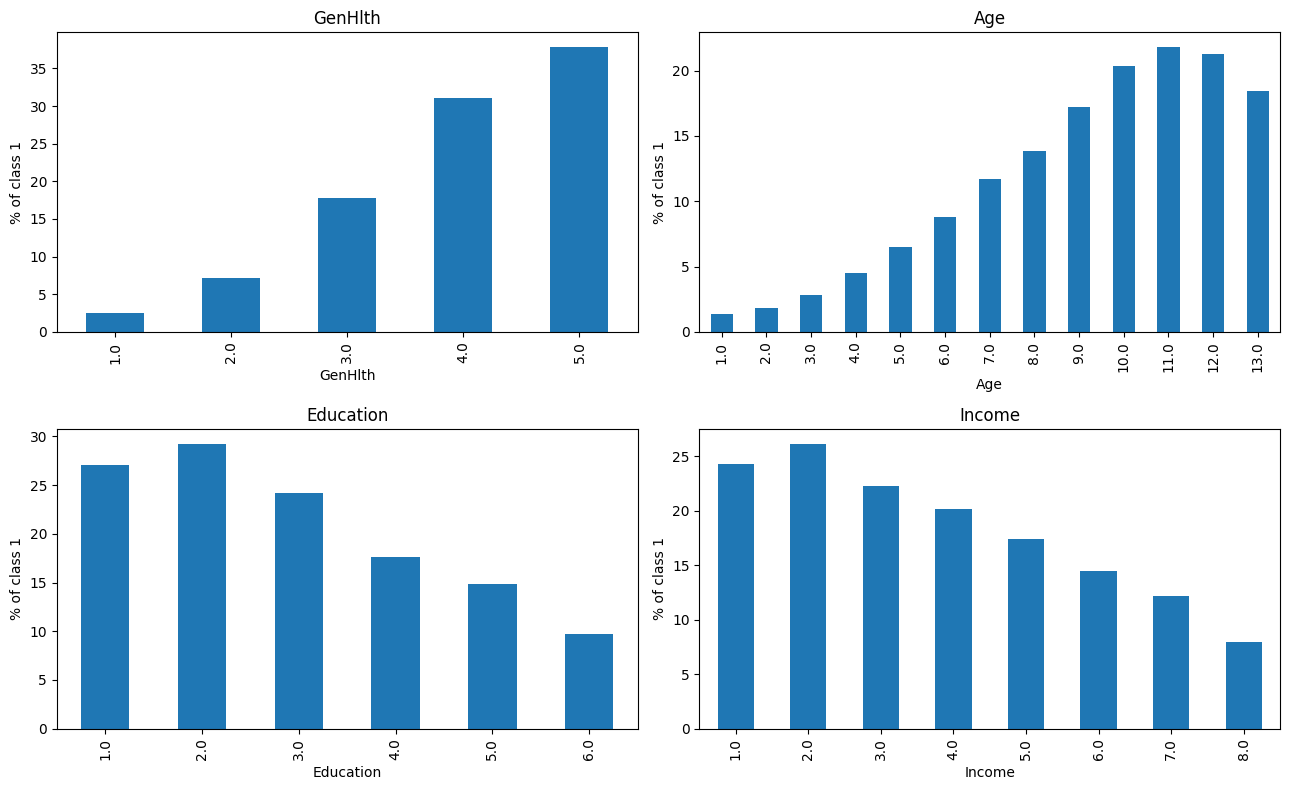

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col in zip(axes.flatten(), ordinal):
    (df.groupby(col)["Diabetes_binary"].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_ylabel("% of class 1")
    ax.set_title(col)

plt.tight_layout()
plt.show()

What we observe: the share of class 1 rises steadily with worse general health, from 2.5% (excellent) to 37.9% (poor). It also rises with age, from 1.4% (18-24) to about 22% (70-74), then drops slightly for the 80+ group (18.5%). It falls as income rises, from about 24-26% in the lowest income groups to 8% in the highest. Education follows the same direction as income.
What we can conclude: these ordered features show clear trends with the target in this dataset.
What we cannot conclude: that age, income or education cause diabetes. These variables are linked to many other factors (lifestyle, access to care...). The small drop after 75 could come from the way the survey was collected, and we cannot explain it from this plot alone.

FR Plus la santé est mauvaise, plus l’âge est élevé et plus le revenu est bas, plus la proportion de classe 1 est grande. Ce sont des tendances, pas des causes.

Features that look uninformative

We use binary_table from section 8 and .abs() (absolute value, which ignores the sign) to find the binary features whose difference is closest to 0, meaning the share of class 1 hardly changes between “no” and “yes”.

.assign(abs_diff=...): adds a new column to the table.
.head(4): shows only the first 4 rows.

FR On cherche les features dont la proportion de classe 1 change à peine entre “non” et “oui” : ce sont les moins liées à la cible.

In [12]:
binary_table.assign(abs_diff=binary_table["difference"].abs()).sort_values("abs_diff").head(4)

,feature,% class 1 when 0,% class 1 when 1,difference,abs_diff
13,Sex,13.0,15.2,2.2,2.2
10,AnyHealthcare,11.5,14.1,2.6,2.6
7,Fruits,15.8,12.9,-2.9,2.9
11,NoDocbcCost,13.6,17.5,3.9,3.9


binary_table.assign(abs_diff=binary_table["difference"].abs()).sort_values("abs_diff").head(4)

# Step 3 – Create TRAIN and TEST

Goal: split the data into two parts. TRAIN is used to learn (preprocessing and model). TEST is kept aside and used only at the end to evaluate the model on data it has never seen.

FR On coupe les données en deux. TRAIN sert à apprendre. TEST est mis de côté et sert seulement à la fin, pour évaluer le modèle sur des données jamais vues.

from sklearn.model_selection import train_test_split: imports the function from scikit-learn, the main machine learning library in Python.
train_test_split(X, y, ...): randomly splits X and y into four parts at once: X_train, X_test, y_train, y_test. The rows of X and y stay matched.
test_size=0.2: 20% of the rows go to TEST and 80% to TRAIN.
stratify=y: keeps the same proportion of class 0 and class 1 in TRAIN and TEST. This matters because class 1 is rare (13.9%). Without it, a random split could give TEST too few or too many class 1 cases.
random_state=42: fixes the randomness so that everyone in the group gets exactly the same split and the same results. The number 42 itself is arbitrary.

FR train_test_split coupe X et y en 4 morceaux. test_size=0.2 met 20 % en TEST. stratify=y garde la même proportion de classe 0/1 dans les deux parties (important car la classe 1 est rare). random_state=42 rend le découpage reproductible pour tout le groupe.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (202944, 21)
X_test : (50736, 21)
y_train: (202944,)
y_test : (50736,)


Expected output: X_train: (202944, 21), X_test: (50736, 21).

Check that the split is stratified
y.value_counts(normalize=True): proportion of each class (we used it in Step 1).
pd.DataFrame({...}): builds a small table to compare the three proportions side by side.

100 and .round(2): convert to percentages and keep 2 decimals.

FR On vérifie que la proportion de classe 1 est quasi identique dans les données complètes, dans TRAIN et dans TEST.

In [14]:
check = pd.DataFrame({
    "Full data (%)": y.value_counts(normalize=True) * 100,
    "TRAIN (%)":     y_train.value_counts(normalize=True) * 100,
    "TEST (%)":      y_test.value_counts(normalize=True) * 100
}).round(2)

print(check, "\n")
print("TRAIN counts:\n", y_train.value_counts(), "\n")
print("TEST counts:\n", y_test.value_counts())

                 Full data (%)  TRAIN (%)  TEST (%)
Diabetes_binary                                    
0.0                      86.07      86.07     86.07
1.0                      13.93      13.93     13.93 

TRAIN counts:
 Diabetes_binary
0.0    174667
1.0     28277
Name: count, dtype: int64 

TEST counts:
 Diabetes_binary
0.0    43667
1.0     7069
Name: count, dtype: int64


Expected output: class 1 is 13.93% in the full data, in TRAIN and in TEST. TRAIN has 28,277 class-1 cases and TEST has 7,069.

Text cell D (observations)

EN
What we observe: TRAIN contains 202,944 rows (80%) and TEST contains 50,736 rows (20%). Class 1 represents 13.93% in the full data, in TRAIN and in TEST, so the stratified split worked.
Decision: from now on, TEST is not touched. We do not balance, resample or explore it to make modeling choices. Anything learned from the data (preprocessing, model parameters) will come from TRAIN only.

Why TEST must stay separate (Q4): TEST is meant to simulate new, unseen people. If the preprocessing or the model “sees” TEST while being fitted, information leaks from TEST into the model (this is called data leakage), and the evaluation becomes too optimistic. We would no longer measure how the model performs on new data, only how well it remembers data it has already seen.

FR TRAIN = 80 %, TEST = 20 %, et la classe 1 vaut 13,93 % partout : le split stratifié a bien marché. À partir de maintenant, on ne touche plus à TEST. Q4 : si le modèle ou le preprocessing voit TEST pendant l’apprentissage, il y a une fuite d’information (data leakage) et l’évaluation est trop optimiste.

# Step 4 – Prepare the features


Goal: transform the input features so that Logistic Regression can use them well. We choose the representation of each feature according to its type (from the “Understanding the Dataset” guide), not according to the numbers in the CSV.

FR On transforme les features pour la régression logistique. Le choix dépend du type de chaque variable (d’après le guide), pas des chiffres du CSV.

Our preprocessing choices
Numerical features (BMI, MentHlth, PhysHlth): we standardize them with StandardScaler. They are measured on very different scales (BMI is around 28, days are between 0 and 30). Standardizing puts them on a comparable scale, which helps Logistic Regression.
Binary features (14 yes/no features): we keep them as they are (passthrough). They already use 0/1, which is a simple and complete representation. No extra encoding is needed.
Ordered categorical features (GenHlth, Age, Education, Income): we use OrdinalEncoder with the categories listed in their true order. This tells the preprocessing that these are ordered categories (for example, Age 9 is the 60-64 group, not 9 years). We then standardize them so that their scale is comparable to the other features.

FR Numériques : on les standardise (échelles très différentes). Binaires : on ne change rien, le 0/1 suffit. Ordinales : on utilise OrdinalEncoder avec l’ordre des catégories indiqué explicitement, puis on standardise.

Build the ColumnTransformer
from sklearn.compose import ColumnTransformer: a tool that applies different preprocessing to different columns and puts the result back together.
from sklearn.pipeline import Pipeline: chains several steps one after the other (here: encode, then scale).
StandardScaler(): for each column, it subtracts the mean and divides by the standard deviation. The result has an average of about 0 and a spread of about 1.
OrdinalEncoder(categories=[...]): turns each category into its position in the order we give. We give the list of categories for each ordered feature, in the same order as the ordinal list.
"passthrough": means “leave these columns unchanged”.
ColumnTransformer([(name, transformer, columns), ...]): each tuple says which preprocessing (transformer) is applied to which columns.

FR ColumnTransformer applique un traitement différent selon les colonnes. Pipeline enchaîne plusieurs étapes. StandardScaler retire la moyenne et divise par l’écart-type. passthrough = on ne touche pas. Chaque tuple = (nom, traitement, colonnes).

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

# Categories of each ordered feature, in the right order (from the guide)
ordinal_categories = [
    [1, 2, 3, 4, 5],            # GenHlth: 1 = excellent ... 5 = poor
    list(range(1, 14)),         # Age: 13 age groups
    list(range(1, 7)),          # Education: 6 levels
    list(range(1, 9))           # Income: 8 levels
]

ordinal_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(categories=ordinal_categories)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical),
    ("ord", ordinal_pipeline, ordinal),
    ("bin", "passthrough", binary)
])

preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['BMI', 'MentHlth', 'PhysHlth']),
                                ('ord',
                                 Pipeline(steps=[('encoder',
                                                  OrdinalEncoder(categories=[[1,
                                                                              2,
                                                                              3,
                                                                              4,
                                                                              5],
                                                                             [1,
                                                                              2,
                                                                              3,
                                                                              4,
                                                                              5,
                                                                              6,
                                                                              7,
                                                                              8,
                                                                              9,
                                                                              10,
                                                                              11,
                                                                              12,
                                                                              13],
                                                                             [1,
                                                                              2,
                                                                              3,
                                                                              4,
                                                                              5,
                                                                              6],
                                                                             [1,
                                                                              2,
                                                                              3,
                                                                              4,
                                                                              5,
                                                                              6,
                                                                              7,
                                                                              8]])),
                                                 ('scaler', StandardScaler())]),
                                 ['GenHlth', 'Age', 'Education', 'Income']),
                                ('bin', 'passthrough',
                                 ['HighBP', 'HighChol', 'CholCheck', 'Smoker',
                                  'Stroke', 'HeartDiseaseorAttack',
                                  'PhysActivity', 'Fruits', 'Veggies',
                                  'HvyAlcoholConsump', 'AnyHealthcare',
                                  'NoDocbcCost', 'DiffWalk', 'Sex'])])

Fit on TRAIN only, then apply to TEST
preprocessor.fit_transform(X_train): fit = learns from TRAIN (for example, the mean and standard deviation of each numerical column). transform = applies the transformation. We do both in one step, on TRAIN only.
preprocessor.transform(X_test): applies what was learned from TRAIN to TEST. There is no fit here, so TEST never influences the preprocessing.
.mean_: the mean learned by the StandardScaler. We check that it matches the TRAIN means.
get_feature_names_out(): the names of the columns after the transformation.

FR fit_transform sur TRAIN : le preprocessing apprend (moyennes, écarts-types) puis transforme. Sur TEST, on appelle seulement transform : on applique ce qui a été appris sur TRAIN, sans jamais refaire fit. C’est ce qui évite la fuite d’information.

In [16]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared  = preprocessor.transform(X_test)

print("X_train prepared:", X_train_prepared.shape)
print("X_test prepared :", X_test_prepared.shape)

print("\nMeans learned from TRAIN:", preprocessor.named_transformers_["num"].mean_.round(2))
print("Means computed on X_train:", X_train[numerical].mean().round(2).values)

print("\nColumn names after preprocessing:")
print(preprocessor.get_feature_names_out())

X_train prepared: (202944, 21)
X_test prepared : (50736, 21)

Means learned from TRAIN: [28.38  3.19  4.25]
Means computed on X_train: [28.38  3.19  4.25]

Column names after preprocessing:
['num__BMI' 'num__MentHlth' 'num__PhysHlth' 'ord__GenHlth' 'ord__Age'
 'ord__Education' 'ord__Income' 'bin__HighBP' 'bin__HighChol'
 'bin__CholCheck' 'bin__Smoker' 'bin__Stroke' 'bin__HeartDiseaseorAttack'
 'bin__PhysActivity' 'bin__Fruits' 'bin__Veggies' 'bin__HvyAlcoholConsump'
 'bin__AnyHealthcare' 'bin__NoDocbcCost' 'bin__DiffWalk' 'bin__Sex']


xpected output: (202944, 21) and (50736, 21). The learned means are [28.38, 3.19, 4.25] and they are identical to the means computed directly on X_train.

What we observe: after preprocessing, the number of columns is still 21. Each row is the same person, but the values are now on comparable scales. On TRAIN, the standardized numerical columns have a mean of about 0 and a standard deviation of about 1. On TEST they are only close to 0 and 1 (for example, about 0.003), which is expected because TEST was transformed with the values learned from TRAIN.
Decision: we keep the binary features unchanged, standardize the numerical ones, and encode the ordered ones in their true order.
Why this matters (Q4): if we had called fit on the full dataset or on TEST, the means and standard deviations would include information from TEST. That would be data leakage.

FR Il y a toujours 21 colonnes. Sur TRAIN, les colonnes standardisées ont moyenne ≈ 0 et écart-type ≈ 1. Sur TEST, elles sont seulement proches de 0 et 1 : c’est normal, car on a utilisé les valeurs apprises sur TRAIN. C’est la preuve que TEST n’a pas influencé le preprocessing.

# STEP 5 – Train Logistic Regression

Goal: fit the complete Pipeline (preprocessing + model) using TRAIN only, then make predictions on TEST.

FR On entraîne le modèle complet (preprocessing + régression logistique) sur TRAIN seulement, puis on prédit sur TEST.

Build and fit the complete Pipeline
LogisticRegression(max_iter=1000): the classification model. It computes a probability that a person belongs to class 1, from a weighted combination of the features. max_iter=1000 allows the algorithm enough steps to converge (the default can be too low and give a warning).
Pipeline([("preprocessor", ...), ("classifier", ...)]): chains the preprocessing from Step 4 and the model. When we call fit, the data goes through the preprocessor first and then into the model.
model.fit(X_train, y_train): learns everything from TRAIN: the means and standard deviations (preprocessing) and the model coefficients. TEST is not used.

Why use a Pipeline? The same transformations are automatically applied in the same order every time, and when we later call predict on TEST, the preprocessing uses only what was learned on TRAIN. This protects us from data leakage.

FR LogisticRegression calcule une probabilité d’appartenir à la classe 1. Pipeline enchaîne le preprocessing et le modèle. fit apprend tout sur TRAIN : moyennes, écarts-types et coefficients. TEST n’est pas utilisé.

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
print("Model fitted on TRAIN.")

In [17]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
print("Model fitted on TRAIN.")

Model fitted on TRAIN.


Predict on TEST
model.predict(X_test): returns the predicted class (0 or 1) for each person in TEST.
model.predict_proba(X_test): returns two columns, the probability of class 0 and the probability of class 1. [:, 1] keeps only the second column, the probability of class 1.
A probability is not yet a class. By default, predict turns it into class 1 when the probability is at least 0.50 (this is the threshold).

FR predict donne la classe (0 ou 1). predict_proba(...)[:, 1] donne la probabilité de classe 1. Par défaut, predict choisit la classe 1 si cette probabilité est ≥ 0,50 (c’est le seuil).

In [18]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:", y_pred[:10])
print("First 5 probabilities of class 1:", y_proba[:5].round(3))

First 10 predicted classes: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
First 5 probabilities of class 1: [0.154 0.291 0.02  0.033 0.481]


Expected output: the first 10 predicted classes are all 0., and the first probabilities are [0.154 0.291 0.02 0.033 0.481]. The fifth person has a probability of 0.481, which is below 0.50, so the predicted class is 0.

# STEP 6 – Evaluate the model

Goal: measure how good the predictions are, using several metrics, because accuracy alone is not enough.

FR On mesure la qualité des prédictions avec plusieurs métriques, car l’accuracy seule ne suffit pas.



confusion_matrix(y_test, y_pred): compares the true classes with the predicted classes and counts the four possible outcomes.
.ravel(): flattens the 2x2 matrix into 4 numbers, in the order TN, FP, FN, TP.
ConfusionMatrixDisplay.from_predictions(...): draws the matrix as a plot.

In scikit-learn, the matrix is read like this: rows = true class, columns = predicted class.

Predicted 0	Predicted 1

True 0	TN (true negative)	FP (false positive)
True 1	FN (false negative)	TP (true positive)

FR Lignes = vraie classe, colonnes = classe prédite. TN : bien prédit “pas de diabète”. TP : bien prédit “diabète”. FP : prédit “diabète” à tort. FN : prédit “pas de diabète” à tort.

Confusion matrix:
 [[42622  1045]
 [ 5953  1116]]
TN = 42622, FP = 1045, FN = 5953, TP = 1116


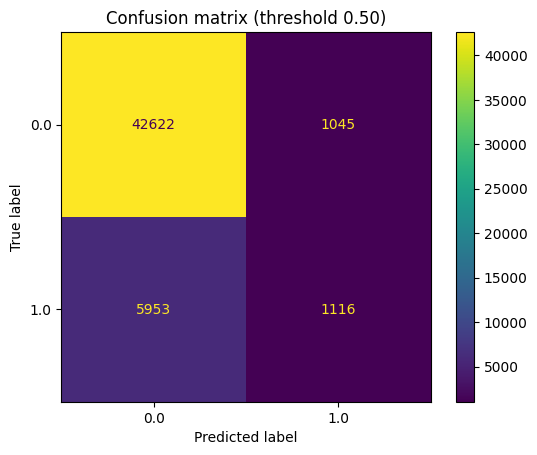

In [19]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score,
                             recall_score, f1_score)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:\n", cm)
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion matrix (threshold 0.50)")
plt.show()

Expected output: TN = 42622, FP = 1045, FN = 5953, TP = 1116.

accuracy_score(y_test, y_pred): (TP + TN) / total. The share of all people classified correctly.
precision_score(...): TP / (TP + FP). Of the people predicted as class 1, how many really are class 1?
recall_score(...): TP / (TP + FN). Of the people who really are class 1, how many did the model find?
f1_score(...): a single number that combines precision and recall (their harmonic mean). It is low if either one is low.

FR Accuracy = part de bonnes prédictions. Précision = parmi ceux prédits “1”, combien le sont vraiment. Recall = parmi ceux qui sont vraiment “1”, combien on en a trouvé. F1 = combine précision et recall.

In [20]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 score : {f1:.3f}")

Accuracy : 0.862
Precision: 0.516
Recall   : 0.158
F1 score : 0.242


Baseline check: why accuracy alone is misleading

A “model” that always predicts class 0 would be correct for every class-0 person. We compute its accuracy to compare.

(y_test == 0).mean(): y_test == 0 gives True/False for each person, and .mean() of True/False values is the proportion of True.

FR On calcule l’accuracy d’un “modèle” qui répondrait toujours 0, pour la comparer à celle de notre modèle.

In [22]:
baseline_accuracy = (y_test == 0).mean()
print(f"Accuracy of always predicting 0: {baseline_accuracy:.3f}")
print(f"Accuracy of our model          : {accuracy:.3f}")
print(f"Number of people predicted as class 1: {int(y_pred.sum())} out of {len(y_pred)}")

Accuracy of always predicting 0: 0.861
Accuracy of our model          : 0.862
Number of people predicted as class 1: 2161 out of 50736


What we observe (confusion matrix): out of 50,736 people in TEST, 42,622 were correctly predicted as class 0 (TN) and 1,116 were correctly predicted as class 1 (TP). The model made 1,045 false positives and 5,953 false negatives.

What false positives and false negatives mean here:

A false positive is a person without diabetes predicted as having prediabetes/diabetes. Consequence: an unnecessary worry, and possibly an unnecessary medical test.
A false negative is a person with prediabetes/diabetes predicted as healthy. Consequence: the person is missed, so early identification and lifestyle changes or treatment may be delayed. In a health setting, this error is usually considered more serious.

What the metrics tell us:

Accuracy (86.2%) looks good, but a model that always says “no diabetes” would get 86.1%. So our model is barely better than doing nothing in terms of accuracy.
Precision (51.6%): when the model predicts class 1, it is right about half of the time.
Recall (15.8%): the model finds only about 16% of the people who really have prediabetes/diabetes. It misses about 84% of them (5,953 out of 7,069).
F1 (0.24) is low because recall is low.

Why accuracy alone is not enough (Q5): because class 1 is rare, the model can be right most of the time simply by predicting class 0. Accuracy hides the fact that it misses most of the people we actually want to detect. Recall and precision show this problem.

Decision: the default threshold of 0.50 makes the model cautious about predicting class 1. In Step 7 we will see what happens if we lower it to 0.40.

FR Sur 7 069 personnes réellement en classe 1, le modèle en retrouve 1 116 seulement (recall ≈ 16 %). L’accuracy de 86,2 % est trompeuse : un modèle qui répond toujours 0 fait 86,1 %. Un faux négatif (malade non détecté) est ici plus grave qu’un faux positif (alerte inutile). On va donc essayer de baisser le seuil à 0,40 au Step 7.

# Step 7 - Probability and threshold

Goal: compare two decision thresholds (0.50 and 0.40) using the probabilities of the Logistic Regression. We do not retrain the model. Only the rule that turns a probability into a class changes.

FR : même modèle, mêmes probabilités. Seule la règle de décision change.


Apply a threshold to the probabilities

y_proba: probabilities of class 1 computed once in Step 5 with predict_proba.
(y_proba >= threshold): True if the probability reaches the threshold.
.astype(int): turns True/False into 1/0 (the predicted class).
A lower threshold means class 1 is predicted more easily.

In [ ]:
y_pred_050 = (y_proba >= 0.50).astype(int)
y_pred_040 = (y_proba >= 0.40).astype(int)

print("Predicted class 1 at 0.50:", y_pred_050.sum())
print("Predicted class 1 at 0.40:", y_pred_040.sum())

Confusion matrix and metrics for each threshold
We reuse the Step 6 functions in a loop, once per threshold. confusion_matrix(...).ravel() gives TN, FP, FN, TP. The results are put in a table (the one requested in the assignment).

In [ ]:
results = []

for threshold, preds in [(0.50, y_pred_050), (0.40, y_pred_040)]:
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    results.append({
        "Threshold": threshold,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy":  round(accuracy_score(y_test, preds), 3),
        "Precision": round(precision_score(y_test, preds), 3),
        "Recall":    round(recall_score(y_test, preds), 3),
        "F1":        round(f1_score(y_test, preds), 3),
    })

threshold_table = pd.DataFrame(results)
threshold_table

Both confusion matrices side by side
plt.subplots(1, 2, ...) creates two plot areas; ConfusionMatrixDisplay.from_predictions(..., ax=ax) draws one matrix in each.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, preds) in zip(axes, [("Threshold 0.50", y_pred_050),
                                    ("Threshold 0.40", y_pred_040)]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

Check what did NOT change
The TEST set, the true labels and the probabilities are identical for both thresholds. Everyone predicted as 1 at 0.50 is still predicted as 1 at 0.40, because lowering the threshold can only add class-1 predictions.

In [ ]:
print("Same TEST set:", y_test.shape)
print("Same probabilities (computed once):", y_proba[:5].round(3))
print("Real class-1 people in TEST:", int(y_test.sum()))
print("Everyone predicted 1 at 0.50 is still predicted 1 at 0.40:",
      bool((y_pred_040 >= y_pred_050).all()))

What we observe: when the threshold goes from 0.50 to 0.40, the model predicts class 1 for more people. True positives go from to and false positives from to. False negatives go from to. Recall goes from to and precision from to.

Why it happens: at 0.40, people with a probability between 0.40 and 0.50 are now predicted as class 1. Some of them really have prediabetes/diabetes (more true positives, fewer false negatives), others do not (more false positives).

What did NOT change: the model (same coefficients and preprocessing), the predicted probabilities, the TEST set and the true labels. Nothing was retrained. Only the decision rule changed.

Interpretation (trade-off): a lower threshold finds more people who really have the condition (higher recall) but creates more false alarms (lower precision). In a health screening context, missing a case is usually more serious than an unnecessary follow-up test, so 0.40 can be justified. The best choice depends on the cost of each error.

# Step 8 – Conclusion

Goal: summarize the most important things learned from the EDA and from the Logistic Regression, and state the limitations of the analysis. Association is not causation.

FR : résumer l’essentiel de l’EDA et du modèle, donner au moins deux limites, ne pas interpréter une association comme une cause.

EDA: The target is imbalanced, with only 13.9% of respondents in class 1. Higher BMI, poorer physical health, older age, lower income and certain conditions (heart disease, stroke, high blood pressure and walking difficulties) are associated with a higher prevalence of prediabetes/diabetes. Some unexpected associations require further investigation.

Logistic Regression: At a 0.50 threshold, accuracy is 86.2%, almost identical to predicting class 0 for everyone (86.1%). However, recall is only 15.8%, meaning the model misses most positive cases (5,953 false negatives out of 7,069). Lowering the threshold to 0.40 increases recall but also changes precision and the number of false positives.

Main takeaway: With imbalanced data, accuracy alone is misleading. The confusion matrix, precision and recall are essential to evaluate performance and select a threshold that balances false negatives and false positives.

FR : on retient surtout que l’accuracy est trompeuse, que le recall est faible à 0,50, et que le seuil règle le compromis entre faux positifs et faux négatifs.

Limitations of this analysis

- Self-reported survey data. The answers (health, habits, income) are what people declare, so they can contain errors and biases. The target also puts prediabetes and diabetes in the same class, which hides differences between the two.
- Simple model, single split. Logistic Regression is a linear model, so it may miss more complex patterns. We also used one TRAIN/TEST split, so the results could change a bit with another split.